Experiment 5: Continuous Bag of Words (CBOW)

Aim: Train a CBOW model to predict a target word from nearby context words, then inspect and save its word vectors.

CBOW is a shallow neural language model. Here, the embeddings of the surrounding words are averaged and used to predict the center word.

1. Import libraries and prepare a sample paragraph

The lab manual permits a self-created English paragraph of 5–10 sentences. This example has eight sentences.

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

paragraph = """
Deep learning helps computers learn patterns from data. Neural networks contain layers of connected units.
Language models learn relationships between words by reading many examples. A word embedding represents
words as vectors, and similar words can have nearby vectors. Continuous bag of words predicts a target word
from nearby context words. The context window determines which neighboring words are used. Training adjusts
the model weights to improve its predictions. After training, word vectors can support similarity searches.
"""

sentences = [
    re.findall(r"[a-z]+", sentence.lower())
    for sentence in re.split(r"[.!?]+", paragraph)
    if sentence.strip()
]

print('Number of sentences:', len(sentences))
print('Tokenized sentences:')
for sentence in sentences:
    print(sentence)

Number of sentences: 8
Tokenized sentences:
['deep', 'learning', 'helps', 'computers', 'learn', 'patterns', 'from', 'data']
['neural', 'networks', 'contain', 'layers', 'of', 'connected', 'units']
['language', 'models', 'learn', 'relationships', 'between', 'words', 'by', 'reading', 'many', 'examples']
['a', 'word', 'embedding', 'represents', 'words', 'as', 'vectors', 'and', 'similar', 'words', 'can', 'have', 'nearby', 'vectors']
['continuous', 'bag', 'of', 'words', 'predicts', 'a', 'target', 'word', 'from', 'nearby', 'context', 'words']
['the', 'context', 'window', 'determines', 'which', 'neighboring', 'words', 'are', 'used']
['training', 'adjusts', 'the', 'model', 'weights', 'to', 'improve', 'its', 'predictions']
['after', 'training', 'word', 'vectors', 'can', 'support', 'similarity', 'searches']


2. Build a vocabulary and generate context–target pairs

For each target word, the model receives up to two words on the left and two words on the right. Zero is reserved for padding at sentence boundaries.

In [2]:
vocabulary = sorted({word for sentence in sentences for word in sentence})
word_to_id = {word: index + 1 for index, word in enumerate(vocabulary)}  # 0 is padding
id_to_word = {index: word for word, index in word_to_id.items()}
vocab_size = len(vocabulary)
window_size = 2
context_length = window_size * 2

contexts = []
targets = []

for sentence in sentences:
    ids = [word_to_id[word] for word in sentence]
    for target_position, target_id in enumerate(ids):
        left = ids[max(0, target_position - window_size):target_position]
        right = ids[target_position + 1:target_position + window_size + 1]
        context = left + right
        context = context[:context_length]
        context += [0] * (context_length - len(context))
        if context:
            contexts.append(context)
            targets.append(target_id)

X = np.asarray(contexts, dtype='int32')
y = np.asarray(targets, dtype='int32')

print('Vocabulary size:', vocab_size)
print('Context-target pairs:', len(X))
print('First context IDs:', X[0])
print('First target word:', id_to_word[y[0]])

Vocabulary size: 59
Context-target pairs: 77
First context IDs: [29 23  0  0]
First target word: deep


In [3]:
def show_context_pair(index):
    context_words = [id_to_word[i] for i in X[index] if i != 0]
    target_word = id_to_word[y[index]]
    print('Context:', context_words)
    print('Target:', target_word)

show_context_pair(0)

Context: ['learning', 'helps']
Target: deep


In [4]:
embedding_dim = 32

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(context_length,)),
    tf.keras.layers.Embedding(
        input_dim=vocab_size + 1,
        output_dim=embedding_dim,
        mask_zero=True,
        name='word_embedding'
    ),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(vocab_size + 1, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ word_embedding (Embedding)           │ (None, 4, 32)               │           1,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 32)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 60)                  │           1,980 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,900 (15.23 KB)

 Trainable params: 3,900 (15.23 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X, y,
    epochs=150,
    batch_size=16,
    verbose=0
)
print('Final training loss:', round(history.history['loss'][-1], 4))
print('Final training accuracy:', round(history.history['accuracy'][-1], 4))

Final training loss: 1.0757
Final training accuracy: 0.9351


4. Inspect predictions and similar words

The sample context is passed through the trained model. Similarity is calculated using cosine similarity between learned embedding vectors

In [6]:
probabilities = model.predict(X[:1], verbose=0)[0]
predicted_id = int(np.argmax(probabilities[1:]) + 1)
print('Context words:', [id_to_word[i] for i in X[0] if i != 0])
print('Actual target:', id_to_word[y[0]])
print('Predicted target:', id_to_word[predicted_id])

embedding_matrix = model.get_layer('word_embedding').get_weights()[0]

def most_similar(word, top_n=5):
    word_id = word_to_id[word]
    vectors = embedding_matrix[1:]
    query = embedding_matrix[word_id]
    norms = np.linalg.norm(vectors, axis=1) * np.linalg.norm(query)
    similarities = (vectors @ query) / np.maximum(norms, 1e-12)
    similarities[word_id - 1] = -1
    best_ids = np.argsort(similarities)[::-1][:top_n] + 1
    return [(id_to_word[i], float(similarities[i - 1])) for i in best_ids]

query_word = 'words'
print(f'Words most similar to {query_word!r}:')
for similar_word, score in most_similar(query_word):
    print(f'{similar_word:15} {score:.4f}')

Context words: ['learning', 'helps']
Actual target: deep
Predicted target: deep
Words most similar to 'words':
determines      0.3878
are             0.3846
continuous      0.2229
and             0.2161
units           0.2084


5. Save the word vectors and plot training loss

Saved vectors to: experiment05_vectors.txt


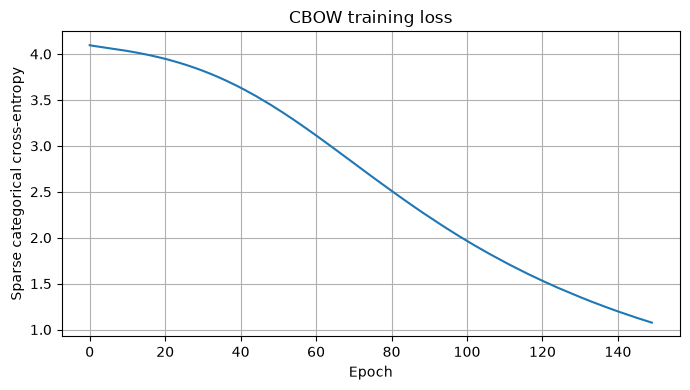

In [7]:
vector_file = 'experiment05_vectors.txt'
with open(vector_file, 'w', encoding='utf-8') as file:
    file.write(f'{vocab_size} {embedding_dim}\n')
    for word, word_id in word_to_id.items():
        vector = embedding_matrix[word_id]
        file.write(word + ' ' + ' '.join(f'{value:.6f}' for value in vector) + '\n')

print('Saved vectors to:', vector_file)

plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'])
plt.title('CBOW training loss')
plt.xlabel('Epoch')
plt.ylabel('Sparse categorical cross-entropy')
plt.grid(True)
plt.tight_layout()
plt.show()

Result

The CBOW model was trained to predict target words from nearby context words. The notebook displays the vocabulary and context-target examples, a sample prediction, similar words, final training metrics, and the saved word-vector file. Since the training paragraph is small, these embeddings are for demonstrating the experiment rather than for general language use.